# Were the SWE-bench Verified records real?

- This notebook tests every record of the SWE-bench Verified leaderboard
  against the record it broke, on the same 500 tasks
  - It is Study A of `preregistration_2.md`, whose design and predictions
    were committed before this analysis was run
  - A submission sets a record when it resolves more tasks than every
    submission dated before it
  - Each record gets the exact McNemar test of Milestone 2, with Holm over
    all the records
- The pedagogical arc:
  - The chain of records
  - Each record against the one it broke
  - How much of the progress came in steps the tasks can resolve
  - Which predictions held
  - 2 extra looks, not pre-registered: the tests without Holm, and how many
    levels the 500 tasks can tell apart

In [1]:
%load_ext autoreload
%autoreload 2

import logging

In [2]:
import helpers.hnotebook as hnotebook

import skill_vs_luck_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmpv4fnvewd.json --HistoryManager.hist_file=:memory:


# Part 1: The chain of records

## Cell 1.1: Find the records

- The data is the pinned snapshot of Milestones 1 and 2: 173 submissions on
  the same 500 tasks, each dated by its folder name
  - The 9 submissions without usable per-task results cannot be in the chain
- Of the submissions with the same date, only the best can set the record
- The earliest submission starts the chain, so every later record has a
  record it broke

In [3]:
# Load the data and find the records.
outcomes, submissions, tasks = utils.load_swebench_dataset("data")
leaderboard = utils.compute_leaderboard(outcomes, submissions)
records = utils.find_records(leaderboard)

print("records=", len(records))
display(records[["date", "label", "score", "n_resolved", "attempts"]])
# Outcome: 31 records, from RAG + Claude 2 at 4.4% on 2023-10-10 to Sonar
# Foundation Agent + Claude 4.5 Opus at 79.2% on 2025-12-05.

records= 31


,date,label,score,n_resolved,attempts
submission,,,,,
20231010_rag_claude2,2023-10-10,RAG + Claude 2,0.044,22,1
20240402_sweagent_gpt4,2024-04-02,SWE-agent + GPT 4 (1106),0.224,112,1
20240509_amazon-q-developer-agent-20240430-dev,2024-05-09,Amazon Q Developer Agent (v20240430-dev),0.256,128,2+
20240612_MASAI_gpt4o,2024-06-12,MASAI + GPT 4o (2024-06-12),0.326,163,2+
20240617_factory_code_droid,2024-06-17,Factory Code Droid,0.370,185,2+
20240628_autocoderover-v20240620,2024-06-28,AutoCodeRover (v20240620) + GPT 4o (2024-05-13),0.384,192,2+
20240721_amazon-q-developer-agent-20240719-dev,2024-07-21,Amazon Q Developer Agent (v20240719-dev),0.388,194,2+
20240820_honeycomb,2024-08-20,Honeycomb,0.406,203,2+
20240824_gru,2024-08-24,Gru(2024-08-24),0.452,226,2+


# Part 2: Each record against the one it broke

## Cell 2.1: Test each record

- `gap` is the score of the new record minus the record it broke
- `only_a` and `only_b` count the tasks that only the new record or only the
  old one solves, and only those tasks say anything about the gap
- `ci_low` and `ci_high` are the 95% paired bootstrap interval of the gap,
  for each record on its own, so they are not adjusted for the 30 tests

In [4]:
# Compare each record with the record it broke.
audit = utils.audit_records(outcomes, records)

print("median_gap=", round(audit["gap"].median(), 4))
display(audit.drop(columns=["previous"]))
# Outcome: only 2 of the 30 records are distinguishable after Holm: SWE-agent +
# GPT 4 (1106), 18.0 points above RAG + Claude 2, and MASAI + GPT 4o, 7.0
# points above the record before it. The median record is 1.5 points above the
# one it broke.

median_gap= 0.015


,date,record,attempts,gap,ci_low,ci_high,only_a,only_b,p_value,p_holm,distinguishable
submission,,,,,,,,,,,
20240402_sweagent_gpt4,2024-04-02,SWE-agent + GPT 4 (1106),1,0.180,0.14400,0.21800,98,8,8.079959e-21,2.423988e-19,True
20240509_amazon-q-developer-agent-20240430-dev,2024-05-09,Amazon Q Developer Agent (v20240430-dev),2+,0.032,-0.00800,0.07200,61,45,1.447823e-01,1.000000e+00,False
20240612_MASAI_gpt4o,2024-06-12,MASAI + GPT 4o (2024-06-12),2+,0.070,0.02800,0.11000,71,36,9.231580e-04,2.677158e-02,True
20240617_factory_code_droid,2024-06-17,Factory Code Droid,2+,0.044,0.00400,0.08400,65,43,4.280722e-02,1.000000e+00,False
20240628_autocoderover-v20240620,2024-06-28,AutoCodeRover (v20240620) + GPT 4o (2024-05-13),2+,0.014,-0.02600,0.05200,56,49,5.583943e-01,1.000000e+00,False
20240721_amazon-q-developer-agent-20240719-dev,2024-07-21,Amazon Q Developer Agent (v20240719-dev),2+,0.004,-0.03600,0.04200,55,53,9.234010e-01,1.000000e+00,False
20240820_honeycomb,2024-08-20,Honeycomb,2+,0.018,-0.02200,0.05800,57,48,4.351145e-01,1.000000e+00,False
20240824_gru,2024-08-24,Gru(2024-08-24),2+,0.046,0.00400,0.08800,71,48,4.326826e-02,1.000000e+00,False
20240924_solver,2024-09-24,Solver (2024-09-12) (2024-09-24),2+,0.002,-0.03400,0.04000,46,45,1.000000e+00,1.000000e+00,False


## Cell 2.2: Plot the records

- The gray staircase is the record over time
- Green records are distinguishable from the record they broke, after Holm

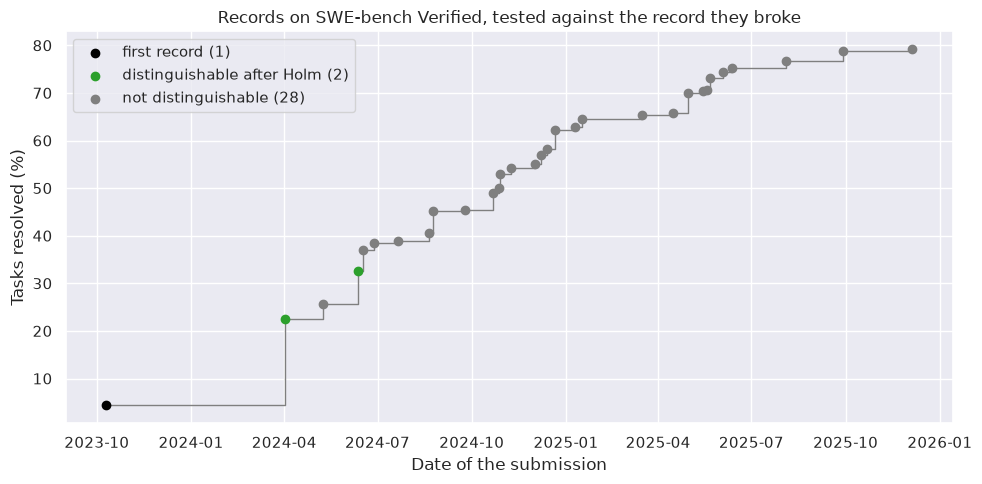

In [5]:
# Plot the records over time.
utils.plot_records(records, audit, figsize=(10, 5))
# Outcome: after MASAI + GPT 4o in June 2024 no record is distinguishable from
# the one it broke, though the next 27 records took the top score from 32.6% to
# 79.2%.

# Part 3: How much of the progress was real

## Cell 3.1: Summarize the audit

- `total_gap` is the score of the last record minus the first, which is the
  sum of all the record gaps
- `p_first_last` tests the last record against the first one
- `distinguishable_share` is the share of `total_gap` that came in the
  records distinguishable after Holm

In [6]:
# Summarize the record audit.
summary = utils.summarize_records(outcomes, records, audit)

display(summary)
# Outcome: the 74.8 points from the first record to the last are clearly real
# (p = 5.2e-113), but only 33% of them came in the 2 distinguishable steps, and
# 25 of the 30 records come from submissions that allow more than 1 attempt.

{'n_records': 30,
 'n_distinguishable': 2,
 'n_multi_attempt': 25,
 'total_gap': 0.7480000000000001,
 'p_first_last': 5.19770488282245e-113,
 'distinguishable_share': 0.33422459893048123}

# Part 4: Which predictions held

## Cell 4.1: Check A1 to A3

- The rules come from `preregistration_2.md`, committed before this analysis
  was run

In [7]:
# Check the pre-registered predictions.
predictions = utils.check_record_predictions(summary)

display(predictions)
# Outcome: A1 and A2 hold and A3 does not: only 2 of the 30 records stand out,
# and 67% of the progress came in steps too small to tell apart one at a time,
# even though the total is clearly real.

,prediction,observed,holds
A1,Fewer than half of the records are distinguish...,2 of 30 records distinguishable,True
A2,The last record is distinguishable from the first,"gap of 74.8 points, exact McNemar p 5.2e-113",True
A3,Most of the progress came in distinguishable s...,33% of the points,False


# Part 5: Extra looks, not pre-registered

## Cell 5.1: The same counts without Holm

- Not pre-registered: this checks how much A1 and A3 depend on the Holm
  adjustment

In [8]:
# Count the records with a raw p-value below 0.05.
raw = audit["p_value"] < 0.05
raw_share = audit.loc[raw, "gap"].sum() / audit["gap"].sum()

print("raw_significant=", int(raw.sum()), "raw_share=", round(raw_share, 3))
# Outcome: without Holm, 6 of the 30 records have p below 0.05 and they carry
# 56% of the points, so A1 holds either way, while A3 only holds without the
# adjustment.

raw_significant= 6 raw_share= 0.564


## Cell 5.2: Levels the tasks can tell apart

- Not pre-registered: going through the records in order, a record starts a
  new level when it is distinguishable from the record that started the
  current level (raw p below 0.05)
- The tests are not adjusted, so the count of levels is rough

In [9]:
# Group the records into levels.
levels = utils.find_distinct_levels(outcomes, records)

print("levels=", len(levels))
display(levels)
# Outcome: the 31 records fall into 12 levels, and each new level is 4.0 to
# 18.0 points above the one before, so on 500 tasks a jump of about 4 points is
# the smallest that stands out.

levels= 12


,date,label,score,gap,p_value,n_records
submission,,,,,,
20231010_rag_claude2,2023-10-10,RAG + Claude 2,0.044,NaN,NaN,1
20240402_sweagent_gpt4,2024-04-02,SWE-agent + GPT 4 (1106),0.224,0.180,8.079959e-21,2
20240612_MASAI_gpt4o,2024-06-12,MASAI + GPT 4o (2024-06-12),0.326,0.102,4.848718e-06,1
20240617_factory_code_droid,2024-06-17,Factory Code Droid,0.370,0.044,4.280722e-02,4
20240824_gru,2024-08-24,Gru(2024-08-24),0.452,0.082,1.073006e-04,3
20241028_solver,2024-10-28,Solver (2024-10-28),0.500,0.048,2.364564e-02,2
20241108_devlo,2024-11-08,devlo (2024-11-08),0.542,0.042,3.751423e-02,3
20241213_devlo,2024-12-13,devlo (2024-12-13),0.582,0.040,1.865726e-02,1
20241221_codestory_midwit_claude-3-5-sonnet_swe-search,2024-12-21,CodeStory Midwit Agent + swe-search,0.622,0.040,4.459752e-02,5


# Part 6: Takeaways

- The SWE-bench Verified record was broken 30 times in this snapshot, but only
  2 of those records are distinguishable from the record they broke
- The progress itself is real: 74.8 points from the first record to the last
  - Since June 2024, 27 records in a row were each within the noise of the
    record before, and together they still added 46.6 points
  - A single new record on 500 tasks says little, while the trend over many
    records says a lot
- 25 of the 30 records come from submissions that allow more than 1 attempt
  per task, so most records are not 1-run scores
- Prediction A3 missed: we expected most of the progress to come in steps
  that stand out, and only 33% did